# Práctica 2 (parte 2): CNNs Preentrenadas (EuroSAT)
## Aprendizaje Profundo - Grado en Inteligencia Artificial
**Universidade da Coruña (UDC)**

---

### Información del Grupo de Prácticas
* **Autores:** Xoel Sánchez Dacoba y Sebastián David Moreno Expósito
* **Código del Grupo de Prácticas:** AP.11.09
* **Fecha:** Noviembre 2026
* **Dataset:** EuroSAT RGB (Sentinel-2, 10 clases de uso de suelo)
* **Cuadernos de la P2:** `P2_1_EuroSAT_CNN_personalizada.ipynb` y `P2_2_EuroSAT_CNN_preentrenadas.ipynb` (este). Para la comparación final, este cuaderno lee los resultados que guarda el cuaderno 1 en `resultados/`.

---

## Índice de Contenidos
1. **[Configuración del Entorno y Reproducibilidad](#sec1)**
2. **[Carga del Dataset y Preprocesado para Redes Preentrenadas](#sec2)**
3. **[Redes Preentrenadas y Estrategias de Reutilización](#sec3)**
4. **[Estrategia 1: Extracción Rápida de Características (6 redes)](#sec4)**
   * 4.1. *Estudio del tamaño de entrada (64, 128 y 224 píxeles)*
5. **[Estrategia 2: Extracción de Características con Aumento de Datos](#sec5)**
6. **[Estrategia 3: Ajuste Fino del Último Bloque (Fine-Tuning parcial)](#sec6)**
7. **[Estrategia 4: Ajuste Fino Completo](#sec7)**
   * 7.1. *Diagnóstico y Estrategia 5: ajuste fino completo corregido*
8. **[Comparación Global: P1, CNN Personalizada y Preentrenadas](#sec8)**
9. **[Conclusiones](#sec9)**

<a id="sec1"></a>
## 1. Configuración del Entorno y Reproducibilidad
Mismas librerías, misma semilla y misma función `reset_seed` que en el cuaderno 1.

In [1]:
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
import keras
from keras import layers, callbacks
import tensorflow_datasets as tfds
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore", message=".*shuffle=True.*")  # aviso inofensivo de Keras con tf.data

SEED = 255256

def reset_seed(seed=SEED):
    """Fija las semillas de Python, NumPy y TensorFlow (se llama antes de crear cada modelo)."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)

reset_seed()
print(f"TensorFlow v: {tf.__version__} | Keras v: {keras.__version__}")
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.set_visible_devices(gpus[0], "GPU")
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print("GPU usada:", tf.config.experimental.get_device_details(gpus[0]).get("device_name"))
else:
    print("No se detectó GPU: este cuaderno es muy lento en CPU")

RESULTS_DIR = "resultados"
os.makedirs(RESULTS_DIR, exist_ok=True)

I0000 00:00:1794946424.857838     742 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794946430.632432     742 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow v: 2.21.0 | Keras v: 3.15.1
GPU usada: NVIDIA GeForce RTX 5060 Ti


<a id="sec2"></a>
## 2. Carga del Dataset y Preprocesado para Redes Preentrenadas

Usamos **la misma partición 70/15/15** que en la P1 y en el cuaderno 1 (se vuelve a comprobar con los recuentos del test). La descarga se hace desde Zenodo, por el motivo explicado en el cuaderno 1.

**Diferencia importante en la normalización.** En la P1 y en el cuaderno 1 dividíamos los píxeles entre 255. Una red preentrenada, en cambio, debe recibir la imagen **preprocesada exactamente como en su entrenamiento original con ImageNet**, porque sus pesos se ajustaron a ese rango de valores. Cada red de `keras.applications` trae su función `preprocess_input`, que espera píxeles en el rango $[0, 255]$:

| Red | Qué hace su `preprocess_input` |
|---|---|
| VGG16, ResNet50 | Pasa de RGB a BGR y resta la media de ImageNet de cada canal (modo *caffe*) |
| MobileNetV2 | Escala a $[-1, 1]$ (modo *tf*) |
| DenseNet121 | Escala a $[0, 1]$ y normaliza con la media y la desviación típica de ImageNet (modo *torch*) |
| EfficientNetB0, ConvNeXtTiny | No hace nada: la normalización va dentro de la propia red |

Por eso aquí el pipeline **deja los píxeles en $[0, 255]$** (solo los pasa a `float32`), y cada modelo aplica su `preprocess_input` como primera operación. Si dividiéramos entre 255 antes, VGG16 o EfficientNet recibirían valores 255 veces menores que los que esperan.

**Tamaño de entrada.** Las redes se entrenaron con imágenes de $224 \times 224$ y EuroSAT tiene $64 \times 64$. Ampliamos cada imagen a $224 \times 224$ con interpolación bilineal (capa `Resizing`, dentro del modelo). Así los objetos aparecen a una escala parecida a la de ImageNet y el último mapa de características tiene $7 \times 7$ posiciones en lugar de $2 \times 2$. En la sección 4.1 medimos si compensa.

In [2]:
def preparar_eurosat():
    """Prepara EuroSAT RGB en tensorflow_datasets descargándolo de Zenodo (solo la primera vez)."""
    builder = tfds.builder("eurosat/rgb")
    if tf.io.gfile.exists(os.path.join(builder.data_dir, "dataset_info.json")):
        return
    builder.builder_config.download_url = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip"
    builder.builder_config.subdir = "EuroSAT_RGB"
    builder.download_and_prepare()

preparar_eurosat()
(raw_train, raw_val, raw_test), ds_info = tfds.load(
    "eurosat/rgb", split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True, with_info=True)
class_names = ds_info.features["label"].names
num_classes = ds_info.features["label"].num_classes

IMG_SHAPE = (64, 64, 3)
IMG_SIZE = 224   # tamaño al que se amplían las imágenes dentro de cada modelo
BATCH_SIZE = 32  # lote menor que en el cuaderno 1: a 224x224 el ajuste fino ocupa mucha memoria de GPU

def preprocess_sample(image, label):
    """Píxeles en [0, 255] como float32 (SIN dividir entre 255) y etiqueta one-hot."""
    return tf.cast(image, tf.float32), tf.one_hot(label, depth=num_classes)

def make_pipeline(ds, shuffle=False):
    ds = ds.map(preprocess_sample, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(buffer_size=10000, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_pipeline(raw_train, shuffle=True)
train_eval_ds = make_pipeline(raw_train)
val_ds = make_pipeline(raw_val)
test_ds = make_pipeline(raw_test)

def labels_of(ds):
    return np.concatenate([y for _, y in ds.as_numpy_iterator()])

y_train, y_val, y_test = labels_of(train_eval_ds), labels_of(val_ds), labels_of(test_ds)
P1_TEST_COUNTS = [437, 436, 473, 379, 372, 301, 393, 454, 353, 452]
assert list(np.bincount(y_test.argmax(1), minlength=num_classes)) == P1_TEST_COUNTS
for x, _ in train_ds.take(1):
    print("Lote de entrada:", x.shape, "| rango:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))
print(f"Train {len(y_train)} | Val {len(y_val)} | Test {len(y_test)} (test idéntico al de la P1)")

Lote de entrada: (32, 64, 64, 3) | rango: 15.0 - 255.0
Train 18900 | Val 4050 | Test 4050 (test idéntico al de la P1)


<a id="sec3"></a>
## 3. Redes Preentrenadas y Estrategias de Reutilización

### Por qué funciona reutilizar una red entrenada con ImageNet
Una CNN entrenada con ImageNet (1,4 millones de imágenes de 1.000 clases) aprende una **jerarquía de características**. Las primeras capas detectan bordes, colores y texturas, que sirven para casi cualquier imagen. Las últimas detectan partes de objetos propias de ImageNet. Con 18.900 imágenes de entrenamiento no podemos aprender desde cero una jerarquía tan rica, pero sí podemos **reutilizar la ya aprendida** y entrenar solo lo necesario.

### Redes elegidas (de `keras.applications`)
Elegimos 6 familias distintas para probar ideas de diseño diferentes:

| Red | Año | Idea principal | Parámetros (sin la parte densa) |
|---|---|---|---|
| VGG16 | 2014 | Pila de convoluciones 3x3 (la del Laboratorio 7) | 14,7 M |
| ResNet50 | 2015 | Conexiones residuales ($x + F(x)$), que permiten redes muy profundas | 23,6 M |
| DenseNet121 | 2017 | Cada capa recibe los mapas de todas las anteriores | 7,0 M |
| MobileNetV2 | 2018 | Convoluciones separables en profundidad: muy ligera | 2,3 M |
| EfficientNetB0 | 2019 | Profundidad, anchura y resolución escaladas a la vez | 4,0 M |
| ConvNeXtTiny | 2022 | CNN modernizada con ideas de los Transformers (kernels 7x7, LayerNorm, GELU) | 27,8 M |

### Estrategias (de menos a más entrenamiento)
1. **Extracción rápida de características:** la red preentrenada (base convolucional, sin su clasificador de 1.000 clases) se pasa **una sola vez** por todas las imágenes y se guardan sus vectores de salida. Después se entrena solo un clasificador denso pequeño sobre esos vectores. Es muy barata, pero no admite aumento de datos (las características quedan fijas).
2. **Extracción de características con aumento de datos:** la base va **congelada** dentro del modelo, de principio a fin, y el aumento de datos se aplica en cada época. Solo se entrena la cabeza, pero cada imagen atraviesa la base en todas las épocas: es más caro.
3. **Ajuste fino parcial (fine-tuning):** partiendo de la estrategia 2 (cabeza ya entrenada), se **descongela el último bloque** de la base y se entrena junto con la cabeza con una tasa de aprendizaje muy baja ($10^{-5}$). Así las características más abstractas, las más ligadas a ImageNet, se adaptan a las imágenes de satélite.
4. **Ajuste fino completo:** igual, pero se descongela **toda** la base.

> Detalle de implementación: la base se llama con `training=False`, de modo que sus capas de Batch Normalization usan siempre las estadísticas aprendidas con ImageNet, también al descongelarlas. Es lo que recomienda Keras: si esas estadísticas se recalcularan con los lotes pequeños de EuroSAT al empezar el ajuste fino, las características cambiarían de golpe y se perdería lo aprendido.

In [3]:
PRETRAINED = {
    "VGG16":          (keras.applications.VGG16,          keras.applications.vgg16.preprocess_input),
    "ResNet50":       (keras.applications.ResNet50,       keras.applications.resnet50.preprocess_input),
    "DenseNet121":    (keras.applications.DenseNet121,    keras.applications.densenet.preprocess_input),
    "MobileNetV2":    (keras.applications.MobileNetV2,    keras.applications.mobilenet_v2.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    "ConvNeXtTiny":   (keras.applications.ConvNeXtTiny,   keras.applications.convnext.preprocess_input),
}

# Capas que forman el último bloque de cada red (las que se descongelan en el ajuste fino parcial)
LAST_BLOCK = {
    "VGG16":          lambda n: n.startswith("block5_"),
    "ResNet50":       lambda n: n.startswith("conv5_"),
    "DenseNet121":    lambda n: n.startswith("conv5_") or n == "bn",
    "MobileNetV2":    lambda n: n.startswith(("block_15_", "block_16_", "Conv_1")),
    "EfficientNetB0": lambda n: n.startswith(("block6", "block7", "top_")),
    "ConvNeXtTiny":   lambda n: n.startswith(("convnext_tiny_stage_3", "layer_normalization")),
}

def make_base(model_name, size=IMG_SIZE):
    """Base convolucional preentrenada con ImageNet, sin clasificador, con GlobalAveragePooling al final."""
    ctor, preprocess = PRETRAINED[model_name]
    base = ctor(include_top=False, weights="imagenet", input_shape=(size, size, 3), pooling="avg")
    return base, preprocess

def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

### Funciones de apoyo (las del cuaderno 1)
`plot_training_history`, `EpochLogger` y un registro común `results_registry`. En este cuaderno cada fila guarda además la **estrategia**, la **red base**, los **parámetros entrenables** y el **tiempo** de cada paso.

In [4]:
results_registry = {}
models_registry = {}

class EpochLogger(callbacks.Callback):
    """Imprime el progreso cada `every` épocas (y la última)."""
    def __init__(self, every=5):
        super().__init__()
        self.every = every
    def _line(self, epoch, logs):
        lr = logs.get("learning_rate")
        lr_txt = f" | lr {float(lr):.1e}" if lr is not None else ""
        return (f"Época {epoch + 1:3d} | loss {logs['loss']:.4f} acc {logs['accuracy']:.4f} | "
                f"val_loss {logs['val_loss']:.4f} val_acc {logs['val_accuracy']:.4f}{lr_txt}")
    def on_epoch_end(self, epoch, logs=None):
        self.last = (epoch, dict(logs))
        if epoch == 0 or (epoch + 1) % self.every == 0:
            print(self._line(epoch, logs))
    def on_train_end(self, logs=None):
        epoch, logs = self.last
        if (epoch + 1) % self.every != 0:
            print(self._line(epoch, logs))

def plot_training_history(history, model_name="Modelo"):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    ax1.plot(epochs, h["loss"], label="Train Loss", color="#1c6ca5", lw=2)
    ax1.plot(epochs, h["val_loss"], label="Val Loss", color="#ff7f0e", lw=2, linestyle="--")
    ax1.set_title(f"{model_name} - Loss"); ax1.set_xlabel("Época"); ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(epochs, h["accuracy"], label="Train Accuracy", color="#1c6ca5", lw=2)
    ax2.plot(epochs, h["val_accuracy"], label="Val Accuracy", color="#ff7f0e", lw=2, linestyle="--")
    ax2.set_title(f"{model_name} - Accuracy"); ax2.set_xlabel("Época"); ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def log_result(key, strategy, base_name, size, model, train_acc, val_acc, test_acc, test_loss, epochs, seconds,
               total_params, trainable_params):
    results_registry[key] = {
        "Estrategia": strategy, "Red base": base_name, "Resolución": size,
        "Parámetros totales": int(total_params), "Parámetros entrenables": int(trainable_params),
        "Épocas": epochs, "Train Acc (%)": round(train_acc * 100, 2), "Val Acc (%)": round(val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2), "Brecha Train-Val (pp)": round((train_acc - val_acc) * 100, 2),
        "Test Loss": round(test_loss, 4), "Tiempo (s)": round(seconds, 1),
    }
    models_registry[key] = model
    print(f"✓ [{key}] Train {train_acc*100:.2f}% | Val {val_acc*100:.2f}% | Test {test_acc*100:.2f}% | "
          f"{trainable_params:,} parámetros entrenables | {seconds:.0f} s")

<a id="sec4"></a>
## 4. Estrategia 1: Extracción Rápida de Características

Para cada una de las 6 redes:
1. Construimos el **extractor**: `Input(64x64x3) → Resizing(224x224) → preprocess_input → base congelada → GlobalAveragePooling`. Cada imagen queda convertida en un vector (512 valores en VGG16, 2.048 en ResNet50, etc.).
2. Pasamos **una vez** las 27.000 imágenes y guardamos los vectores.
3. Entrenamos sobre esos vectores una **cabeza** pequeña: `Dropout(0.2) → Dense(256, ReLU) → Dropout(0.5) → Dense(10, softmax)`, con Adam ($10^{-3}$) y Early Stopping (paciencia 8).

En el Laboratorio 7 se aplanaba el mapa final de VGG16 ($5 \times 5 \times 512$) con `Flatten`. Aquí usamos **GlobalAveragePooling** (la media de cada canal sobre todas las posiciones): los vectores son mucho más pequeños, la cabeza tiene menos parámetros (menos sobreajuste) y el vector no depende de la posición de cada patrón dentro de la imagen.

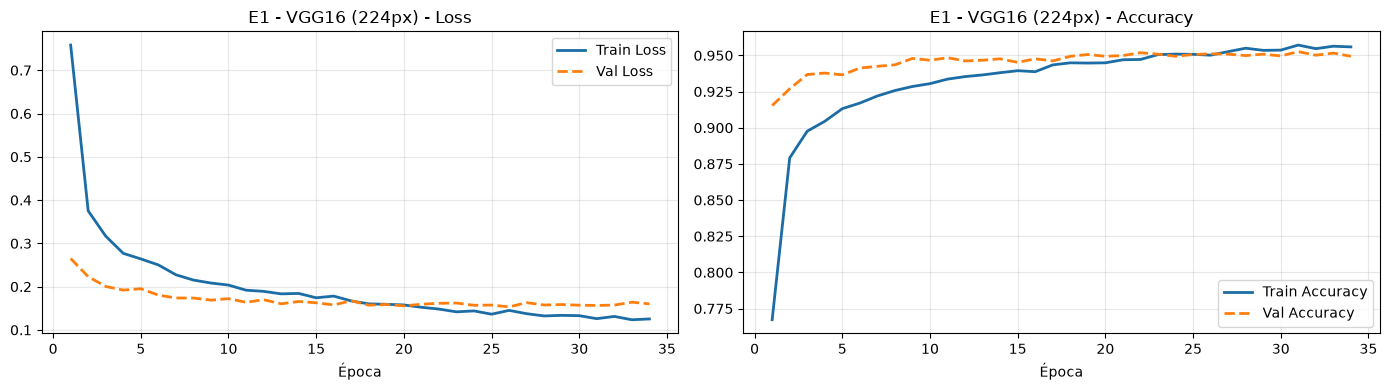

✓ [E1 Extracción rápida - VGG16 (224px)] Train 98.81% | Val 95.11% | Test 95.33% | 133,898 parámetros entrenables | 141 s
   vector de características: 512 | extracción 99 s | cabeza 41 s



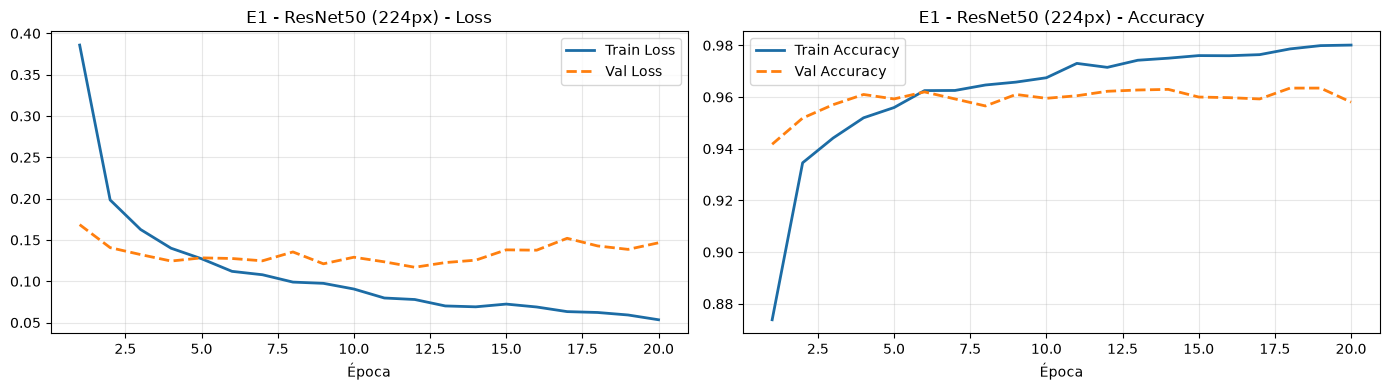

✓ [E1 Extracción rápida - ResNet50 (224px)] Train 99.29% | Val 96.22% | Test 96.44% | 527,114 parámetros entrenables | 70 s
   vector de características: 2048 | extracción 45 s | cabeza 25 s



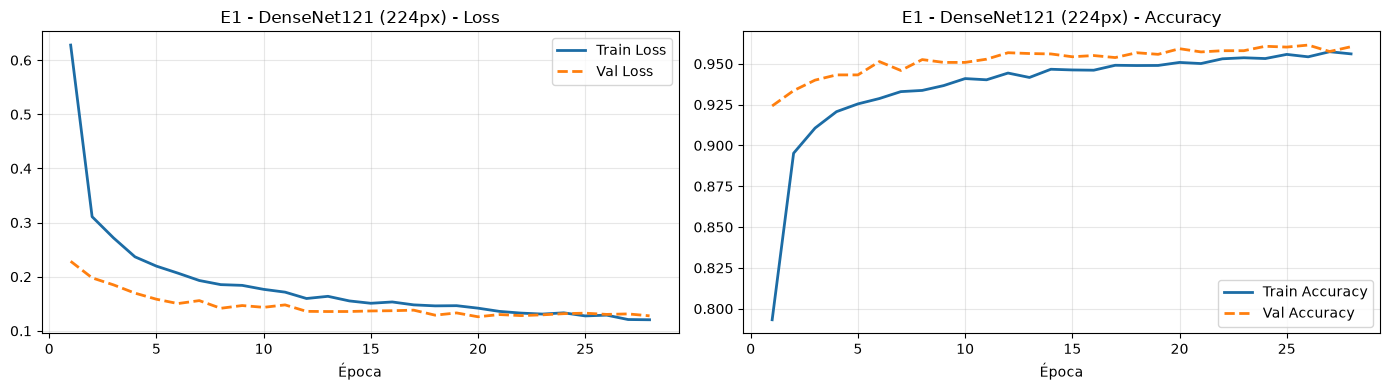

✓ [E1 Extracción rápida - DenseNet121 (224px)] Train 98.42% | Val 95.93% | Test 95.56% | 264,970 parámetros entrenables | 97 s
   vector de características: 1024 | extracción 71 s | cabeza 26 s



E0000 00:00:1794946819.876688     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946820.283426     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946820.965278     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946821.302890     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946833.456887     805 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (4 outputs left out)

E0000 00:00:1794946843.129049     800 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946843.376802     800 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946843.693231     800 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946844.895545     800 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


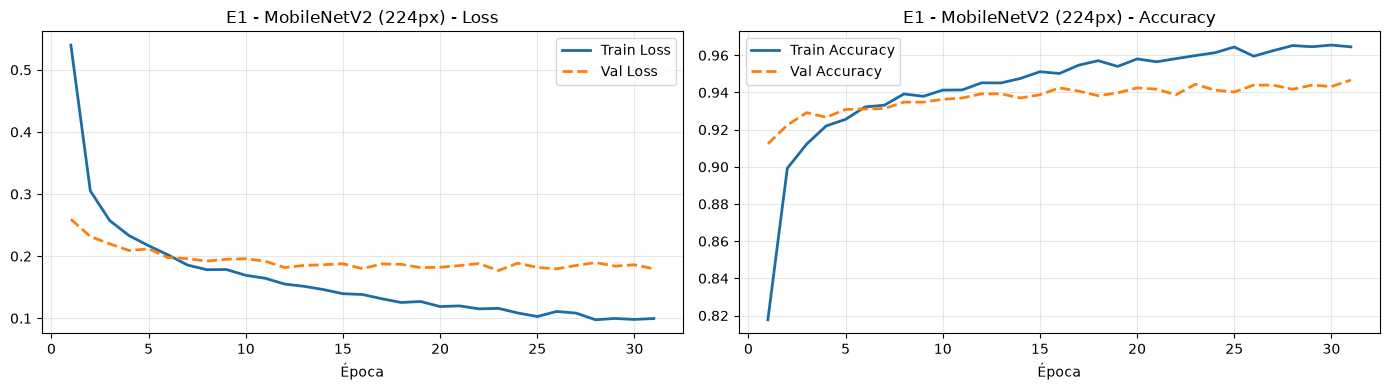

✓ [E1 Extracción rápida - MobileNetV2 (224px)] Train 98.74% | Val 94.44% | Test 94.32% | 330,506 parámetros entrenables | 114 s
   vector de características: 1280 | extracción 35 s | cabeza 79 s



E0000 00:00:1794946941.281020     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946941.833123     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946942.207855     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946942.738544     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946944.050512     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (6 outputs left out)

E0000 00:00:1794946972.955322     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946974.287698     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946974.837958     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794946975.301702     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


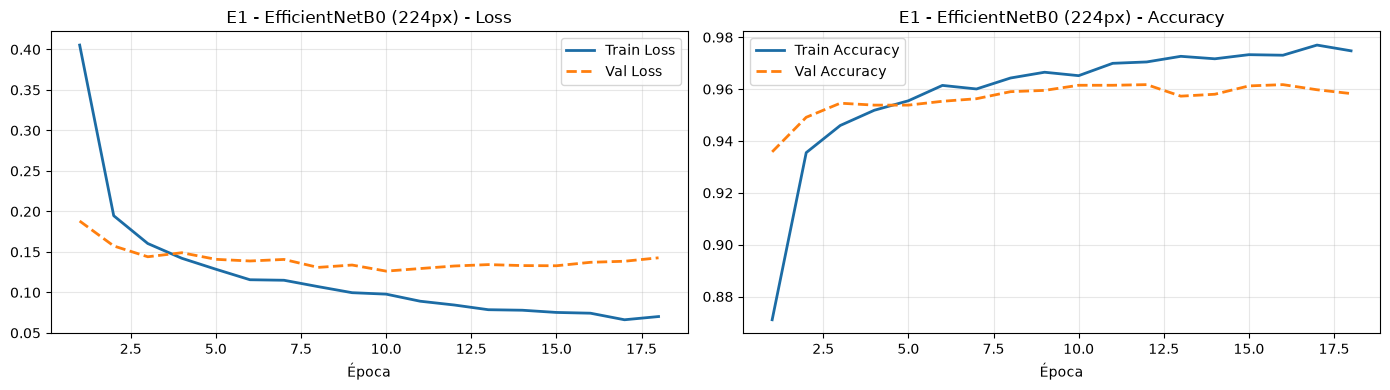

✓ [E1 Extracción rápida - EfficientNetB0 (224px)] Train 98.64% | Val 96.15% | Test 96.27% | 330,506 parámetros entrenables | 58 s
   vector de características: 1280 | extracción 42 s | cabeza 16 s



E0000 00:00:1794947003.857090     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947004.134023     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947005.193056     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947006.583276     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947040.432988     800 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (3 outputs left out)

E0000 00:00:1794947060.440077     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947064.030244     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947066.685220     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794947068.053053     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


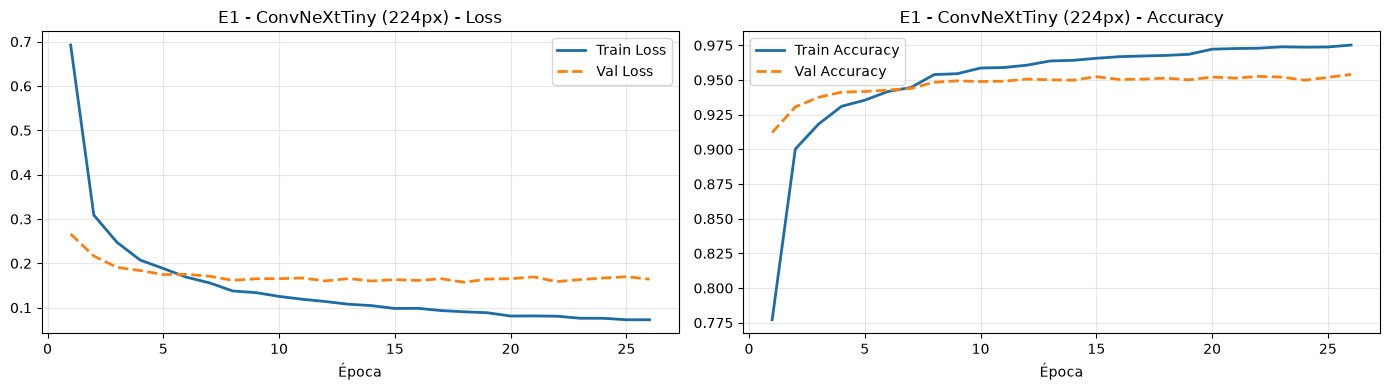

✓ [E1 Extracción rápida - ConvNeXtTiny (224px)] Train 99.37% | Val 95.14% | Test 95.33% | 199,434 parámetros entrenables | 98 s
   vector de características: 768 | extracción 76 s | cabeza 22 s



In [5]:
def build_extractor(model_name, size=IMG_SIZE):
    base, preprocess = make_base(model_name, size)
    base.trainable = False
    inputs = keras.Input(shape=IMG_SHAPE)
    x = layers.Resizing(size, size, interpolation="bilinear")(inputs) if size != 64 else inputs
    x = preprocess(x)
    outputs = base(x, training=False)
    return keras.Model(inputs, outputs, name=f"extractor_{model_name}"), base

def extract_features(extractor):
    only_images = lambda ds: ds.map(lambda x, y: x)
    return [extractor.predict(only_images(ds), verbose=0) for ds in (train_eval_ds, val_ds, test_ds)]

def build_head(feat_dim):
    inputs = keras.Input(shape=(feat_dim,))
    x = layers.Dropout(0.2)(inputs)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs)

def feature_extraction_experiment(model_name, size=IMG_SIZE, show_plot=True):
    reset_seed()
    extractor, base = build_extractor(model_name, size)
    t0 = time.time()
    f_train, f_val, f_test = extract_features(extractor)
    t_extract = time.time() - t0
    reset_seed()
    head = build_head(f_train.shape[1])
    head.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = head.fit(f_train, y_train, validation_data=(f_val, y_val), epochs=60, batch_size=128, verbose=0,
                    callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)])
    t_train = time.time() - t0
    _, tr_acc = head.evaluate(f_train, y_train, verbose=0)
    _, va_acc = head.evaluate(f_val, y_val, verbose=0)
    te_loss, te_acc = head.evaluate(f_test, y_test, verbose=0)
    if show_plot:
        plot_training_history(hist, f"E1 - {model_name} ({size}px)")
    log_result(f"E1 Extracción rápida - {model_name} ({size}px)", "1. Extracción rápida", model_name, size, head,
               tr_acc, va_acc, te_acc, te_loss, len(hist.history["loss"]), t_extract + t_train,
               base.count_params() + head.count_params(), count_trainable(head))
    print(f"   vector de características: {f_train.shape[1]} | extracción {t_extract:.0f} s | cabeza {t_train:.0f} s\n")
    return hist

for name in PRETRAINED:
    feature_extraction_experiment(name)

,Red base,Parámetros totales,Parámetros entrenables,Train Acc (%),Val Acc (%),Test Acc (%),Brecha Train-Val (pp),Tiempo (s)
E1 Extracción rápida - ResNet50 (224px),ResNet50,24114826,527114,99.29,96.22,96.44,3.07,70.2
E1 Extracción rápida - EfficientNetB0 (224px),EfficientNetB0,4380077,330506,98.64,96.15,96.27,2.49,58.0
E1 Extracción rápida - DenseNet121 (224px),DenseNet121,7302474,264970,98.42,95.93,95.56,2.5,96.9
E1 Extracción rápida - ConvNeXtTiny (224px),ConvNeXtTiny,28019562,199434,99.37,95.14,95.33,4.23,98.4
E1 Extracción rápida - VGG16 (224px),VGG16,14848586,133898,98.81,95.11,95.33,3.7,140.6
E1 Extracción rápida - MobileNetV2 (224px),MobileNetV2,2588490,330506,98.74,94.44,94.32,4.29,114.0


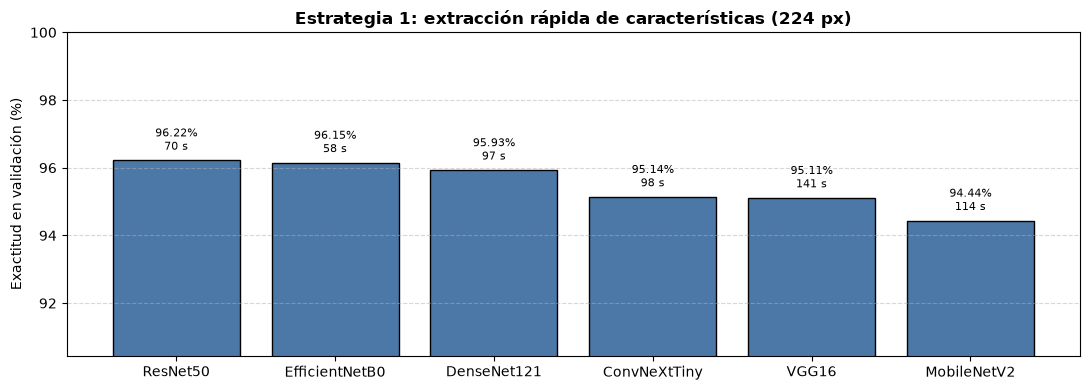

Redes que pasan a las estrategias 2, 3 y 4: ['ResNet50', 'EfficientNetB0']


In [6]:
df_e1 = pd.DataFrame({k: v for k, v in results_registry.items() if k.startswith("E1")}).T
df_e1 = df_e1.sort_values("Val Acc (%)", ascending=False)
display(df_e1[["Red base", "Parámetros totales", "Parámetros entrenables", "Train Acc (%)", "Val Acc (%)",
               "Test Acc (%)", "Brecha Train-Val (pp)", "Tiempo (s)"]])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(df_e1["Red base"], df_e1["Val Acc (%)"], color="#4c78a8", edgecolor="black")
for bar, secs in zip(bars, df_e1["Tiempo (s)"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{bar.get_height():.2f}%\n{secs:.0f} s",
            ha="center", va="bottom", fontsize=8)
ax.set_ylim(df_e1["Val Acc (%)"].min() - 4, 100)
ax.set_ylabel("Exactitud en validación (%)")
ax.set_title("Estrategia 1: extracción rápida de características (224 px)", fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

TOP_MODELS = list(df_e1["Red base"].iloc[:2])  # las 2 mejores en VALIDACIÓN pasan a las estrategias 2-4
print("Redes que pasan a las estrategias 2, 3 y 4:", TOP_MODELS)

### Comentarios de la Estrategia 1
* **Todas las redes funcionan muy bien sin entrenar ni una sola de sus capas convolucionales:** entre el 94,44% (MobileNetV2) y el 96,22% (ResNet50) en validación. Entrenando solo una cabeza de 0,13-0,53 M de parámetros, **ResNet50 (96,44% en test) y EfficientNetB0 (96,27%) superan a la mejor CNN propia del cuaderno 1** (96,15%), y DenseNet121 la supera en validación (95,93% frente a 95,70%). En lugar de los 19 minutos de entrenamiento del Modelo 9, tardan entre **58 y 97 segundos**, extracción incluida. Las características aprendidas con ImageNet (bordes, texturas, patrones repetidos) sirven también para imágenes de satélite, aunque ImageNet no contiene fotos aéreas.
* **Ranking:** ResNet50 ≈ EfficientNetB0 > DenseNet121 > ConvNeXtTiny ≈ VGG16 > MobileNetV2. Las diferencias entre las cuatro primeras son de ~1 punto. Que una red sea más moderna o tenga más parámetros **no garantiza mejores características fijas** para otro dominio: ConvNeXtTiny (2022, 28 M) queda por detrás de ResNet50 (2015, 24 M) y de EfficientNetB0 (2019, 4 M), y su cabeza es, junto con la de MobileNetV2, la que más sobreajusta (brecha de 4,2 y 4,3 puntos). MobileNetV2, diseñada para ser ligera, es la que peores características da.
* **La relación calidad/coste más notable es la de EfficientNetB0:** el 96,27% en test con una base de solo 4,0 M de parámetros, y una de las extracciones más rápidas (42 s).
* Hay algo de sobreajuste en todas las cabezas (brecha de 2,5 a 4,3 puntos), moderado gracias al Dropout y a Early Stopping.
* Pasan a las estrategias 2-4 las dos mejores en validación: **ResNet50 y EfficientNetB0**.

### 4.1. Estudio del tamaño de entrada
¿Compensa ampliar las imágenes de 64 a 224 píxeles? Repetimos la extracción rápida con la mejor red a 64 px (sin ampliar), 128 px y 224 px (ya calculado).

✓ [E1 Extracción rápida - ResNet50 (64px)] Train 97.05% | Val 92.47% | Test 93.38% | 527,114 parámetros entrenables | 34 s
   vector de características: 2048 | extracción 19 s | cabeza 15 s



✓ [E1 Extracción rápida - ResNet50 (128px)] Train 98.79% | Val 95.51% | Test 95.56% | 527,114 parámetros entrenables | 40 s
   vector de características: 2048 | extracción 26 s | cabeza 15 s



,Resolución,Train Acc (%),Val Acc (%),Test Acc (%),Tiempo (s)
E1 Extracción rápida - ResNet50 (64px),64,97.05,92.47,93.38,34.1
E1 Extracción rápida - ResNet50 (128px),128,98.79,95.51,95.56,40.5
E1 Extracción rápida - ResNet50 (224px),224,99.29,96.22,96.44,70.2


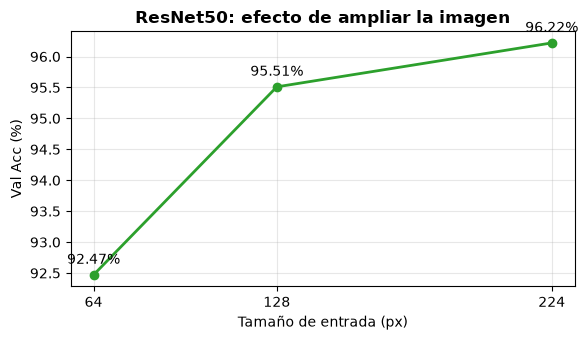

In [7]:
best_e1 = TOP_MODELS[0]
for size in (64, 128):
    feature_extraction_experiment(best_e1, size=size, show_plot=False)

df_res = pd.DataFrame({k: v for k, v in results_registry.items()
                       if k.startswith("E1") and v["Red base"] == best_e1}).T.sort_values("Resolución")
display(df_res[["Resolución", "Train Acc (%)", "Val Acc (%)", "Test Acc (%)", "Tiempo (s)"]])
plt.figure(figsize=(6, 3.5))
plt.plot(df_res["Resolución"], df_res["Val Acc (%)"], "o-", lw=2, color="#2ca02c")
for r, a in zip(df_res["Resolución"], df_res["Val Acc (%)"]):
    plt.annotate(f"{a:.2f}%", (r, a), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xticks([64, 128, 224]); plt.xlabel("Tamaño de entrada (px)"); plt.ylabel("Val Acc (%)")
plt.title(f"{best_e1}: efecto de ampliar la imagen", fontweight="bold"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Comentarios del estudio de resolución
* **Ampliar la imagen compensa claramente:** 92,47% (64 px) → 95,51% (128 px) → 96,22% (224 px) en validación. El coste de extracción solo pasa de 34 a 70 segundos.
* **Por qué:** ResNet50 reduce la imagen 32 veces antes del GlobalAveragePooling. A 64 px el último mapa tiene $2 \times 2$ posiciones y a 224 px tiene $7 \times 7$. Además, sus filtros se aprendieron con objetos que ocupan muchos píxeles en imágenes de 224x224; al ampliar, las texturas de EuroSAT (hileras de cultivos, manzanas de casas) quedan a una escala más parecida a la que esos filtros saben detectar.
* Ampliar no añade información (la interpolación bilineal no crea detalle nuevo): solo adapta la escala de la imagen a la red. Por eso la mejora se va reduciendo: +3,0 puntos de 64 a 128 y +0,7 de 128 a 224.

<a id="sec5"></a>
## 5. Estrategia 2: Extracción de Características con Aumento de Datos

Con las 2 mejores redes de la estrategia 1 construimos el modelo completo:

`Input(64x64x3) → aumento de datos → Resizing(224) → preprocess_input → base CONGELADA → Dropout(0.2) → Dense(256) → Dropout(0.5) → Dense(10)`

El aumento de datos es el del cuaderno 1 (volteos horizontales y verticales, giros de hasta 90°, desplazamientos y zoom del 10%, con relleno por reflexión). Como la base está congelada, solo se entrenan los ~0,3-0,5 M parámetros de la cabeza, pero cada imagen atraviesa la base en cada época. Adam $10^{-3}$, hasta 15 épocas, Early Stopping con paciencia 4.


===== ResNet50: 527,114 parámetros entrenables de 24,114,826 =====


Época   1 | loss 0.4737 acc 0.8422 | val_loss 0.2945 val_acc 0.9035


Época   2 | loss 0.3346 acc 0.8888 | val_loss 0.2995 val_acc 0.9059


Época   3 | loss 0.2952 acc 0.9033 | val_loss 0.2698 val_acc 0.9173


Época   4 | loss 0.2748 acc 0.9089 | val_loss 0.3328 val_acc 0.9002


Época   5 | loss 0.2661 acc 0.9120 | val_loss 0.3219 val_acc 0.9040


Época   6 | loss 0.2567 acc 0.9129 | val_loss 0.2817 val_acc 0.9185


Época   7 | loss 0.2558 acc 0.9156 | val_loss 0.2753 val_acc 0.9170


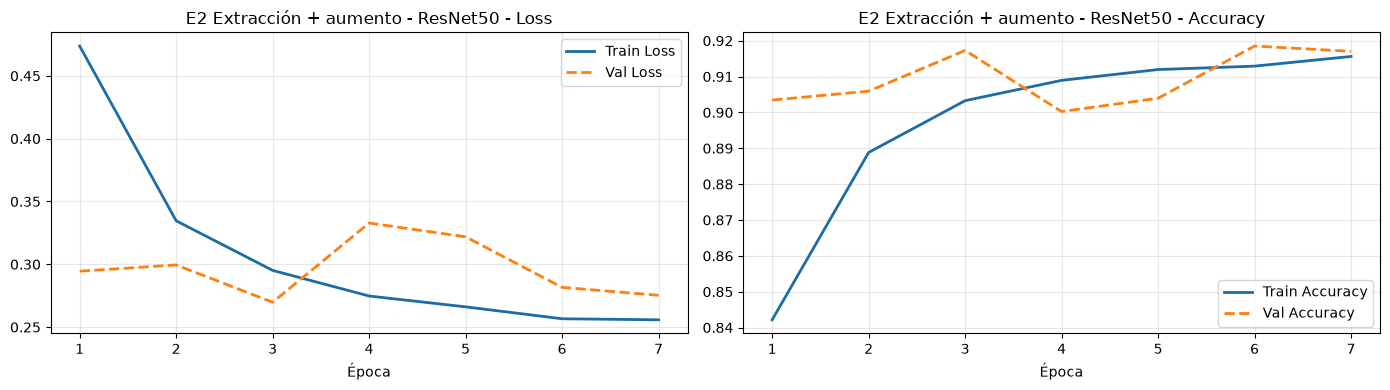

✓ [E2 Extracción + aumento - ResNet50] Train 92.56% | Val 91.73% | Test 92.44% | 527,114 parámetros entrenables | 355 s



===== EfficientNetB0: 330,506 parámetros entrenables de 4,380,077 =====


Época   1 | loss 0.5363 acc 0.8184 | val_loss 0.3271 val_acc 0.8889


Época   2 | loss 0.3837 acc 0.8682 | val_loss 0.2850 val_acc 0.9032


Época   3 | loss 0.3507 acc 0.8808 | val_loss 0.2810 val_acc 0.9052


Época   4 | loss 0.3224 acc 0.8909 | val_loss 0.2591 val_acc 0.9133


Época   5 | loss 0.3207 acc 0.8909 | val_loss 0.3041 val_acc 0.8988


Época   6 | loss 0.3150 acc 0.8920 | val_loss 0.3260 val_acc 0.8931


Época   7 | loss 0.3126 acc 0.8938 | val_loss 0.2818 val_acc 0.9081


Época   8 | loss 0.2937 acc 0.9019 | val_loss 0.2985 val_acc 0.9052


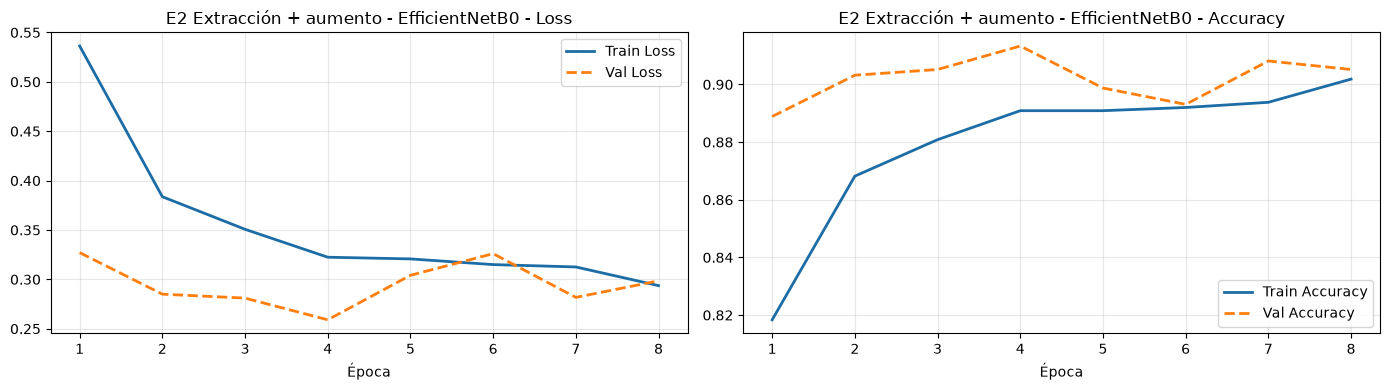

✓ [E2 Extracción + aumento - EfficientNetB0] Train 92.60% | Val 91.33% | Test 93.11% | 330,506 parámetros entrenables | 313 s


In [8]:
def make_augmentation(kind="full"):
    """'full': el aumento del cuaderno 1. 'flips': solo volteos (se usa en la estrategia 5)."""
    if kind == "flips":
        return keras.Sequential([layers.RandomFlip("horizontal_and_vertical")], name="data_augmentation")
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25, fill_mode="reflect"),
        layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
    ], name="data_augmentation")

def build_end_to_end(model_name, size=IMG_SIZE, aug="full"):
    """Modelo completo: aumento -> Resizing -> preprocess_input -> base (congelada) -> cabeza."""
    base, preprocess = make_base(model_name, size)
    base.trainable = False
    inputs = keras.Input(shape=IMG_SHAPE)
    x = make_augmentation(aug)(inputs)
    x = layers.Resizing(size, size, interpolation="bilinear")(x)
    x = preprocess(x)
    x = base(x, training=False)  # BatchNorm de la base siempre en modo inferencia
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"{model_name}_e2e"), base

def train_and_log(key, strategy, model_name, model, optimizer, epochs, patience, every=1, extra_callbacks=None):
    model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])
    cbs = [EpochLogger(every)] + (extra_callbacks or [])
    if patience is not None:  # patience=None -> sin Early Stopping (se usan los pesos de la última época)
        cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0, callbacks=cbs)
    seconds = time.time() - t0
    plot_training_history(hist, key)
    _, tr_acc = model.evaluate(train_eval_ds, verbose=0)
    _, va_acc = model.evaluate(val_ds, verbose=0)
    te_loss, te_acc = model.evaluate(test_ds, verbose=0)
    log_result(key, strategy, model_name, IMG_SIZE, model, tr_acc, va_acc, te_acc, te_loss,
               len(hist.history["loss"]), seconds, model.count_params(), count_trainable(model))
    return hist

e2_weights = {}  # pesos al final de la estrategia 2: punto de partida del ajuste fino
for name in TOP_MODELS:
    reset_seed()
    model, base = build_end_to_end(name)
    print(f"\n===== {name}: {count_trainable(model):,} parámetros entrenables de {model.count_params():,} =====")
    train_and_log(f"E2 Extracción + aumento - {name}", "2. Extracción + aumento", name, model,
                  keras.optimizers.Adam(1e-3), epochs=15, patience=4)
    e2_weights[name] = model.get_weights()

### Comentarios de la Estrategia 2
* **Resultado peor que la estrategia 1:** ResNet50 91,73% en validación (frente a 96,22%) y EfficientNetB0 91,33% (frente a 96,15%), con unos ~5 minutos de entrenamiento en lugar de ~1.
* **Es infrajuste, no sobreajuste:** la exactitud de entrenamiento con los pesos finales es solo del ~92,6% (frente al ~99% de la estrategia 1) y la brecha baja a ~1 punto. El aumento de datos sirve para combatir el sobreajuste, y aquí había poco (~3 puntos en la estrategia 1).
* `EarlyStopping` cortó el entrenamiento en las épocas 7 y 8, porque la pérdida de validación oscila de una época a otra. Lo analizamos en la sección 7.1.

<a id="sec6"></a>
## 6. Estrategia 3: Ajuste Fino del Último Bloque

Seguimos los pasos del Laboratorio 7:
1. Partimos del modelo de la estrategia 2: la cabeza ya está entrenada. Si la entrenáramos a la vez que descongelamos la base, los gradientes grandes de una cabeza aleatoria destruirían las características preentrenadas.
2. **Descongelamos solo el último bloque** de la base (`block5` en VGG16, `conv5` en ResNet50 y DenseNet121, `stage_3` en ConvNeXtTiny, `block6`-`block7` en EfficientNetB0, los dos últimos bloques en MobileNetV2).
3. Entrenamos con una **tasa de aprendizaje muy baja**, Adam $10^{-5}$, para modificar poco a poco los pesos ya aprendidos. Hasta 15 épocas, Early Stopping con paciencia 4.


===== ResNet50: 15,503,114 parámetros entrenables de 24,114,826 =====


Época   1 | loss 0.3856 acc 0.8816 | val_loss 0.2289 val_acc 0.9286


Época   2 | loss 0.2347 acc 0.9247 | val_loss 0.2171 val_acc 0.9309


Época   3 | loss 0.2009 acc 0.9352 | val_loss 0.2054 val_acc 0.9360


Época   4 | loss 0.1747 acc 0.9432 | val_loss 0.3756 val_acc 0.8926


Época   5 | loss 0.1565 acc 0.9496 | val_loss 0.2749 val_acc 0.9215


Época   6 | loss 0.1490 acc 0.9517 | val_loss 0.3314 val_acc 0.9059


Época   7 | loss 0.1332 acc 0.9563 | val_loss 0.4484 val_acc 0.8941


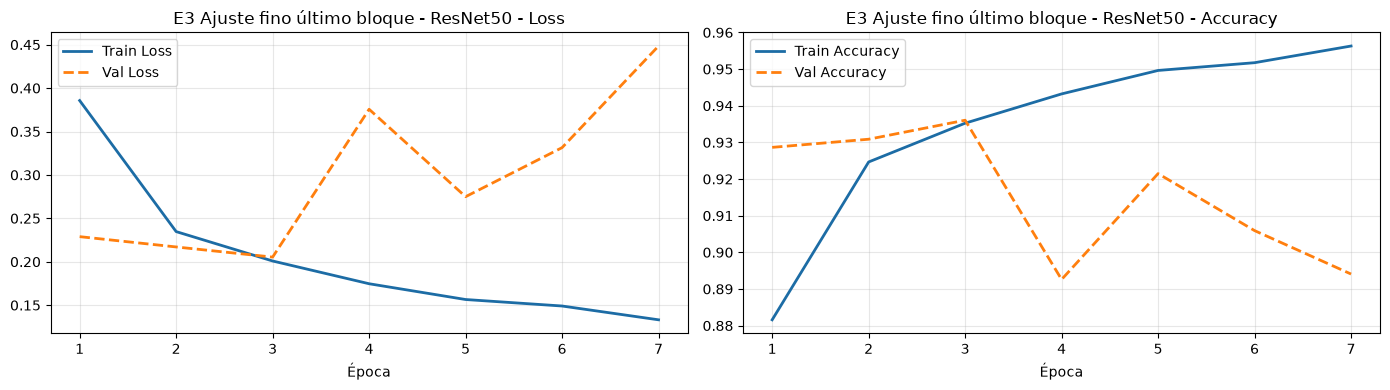

✓ [E3 Ajuste fino último bloque - ResNet50] Train 94.72% | Val 93.60% | Test 94.05% | 15,503,114 parámetros entrenables | 502 s



===== EfficientNetB0: 3,486,246 parámetros entrenables de 4,380,077 =====


E0000 00:00:1794948638.992753     742 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_e2e_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Época   1 | loss 0.8722 acc 0.7448 | val_loss 0.4093 val_acc 0.8743


Época   2 | loss 0.5145 acc 0.8375 | val_loss 0.3445 val_acc 0.8965


Época   3 | loss 0.4209 acc 0.8659 | val_loss 0.3092 val_acc 0.9081


... (2 outputs left out)

Época   6 | loss 0.3184 acc 0.8947 | val_loss 0.2915 val_acc 0.9128


Época   7 | loss 0.3070 acc 0.9010 | val_loss 0.2944 val_acc 0.9146


Época   8 | loss 0.2892 acc 0.9066 | val_loss 0.3175 val_acc 0.9057


Época   9 | loss 0.2770 acc 0.9115 | val_loss 0.3228 val_acc 0.9025


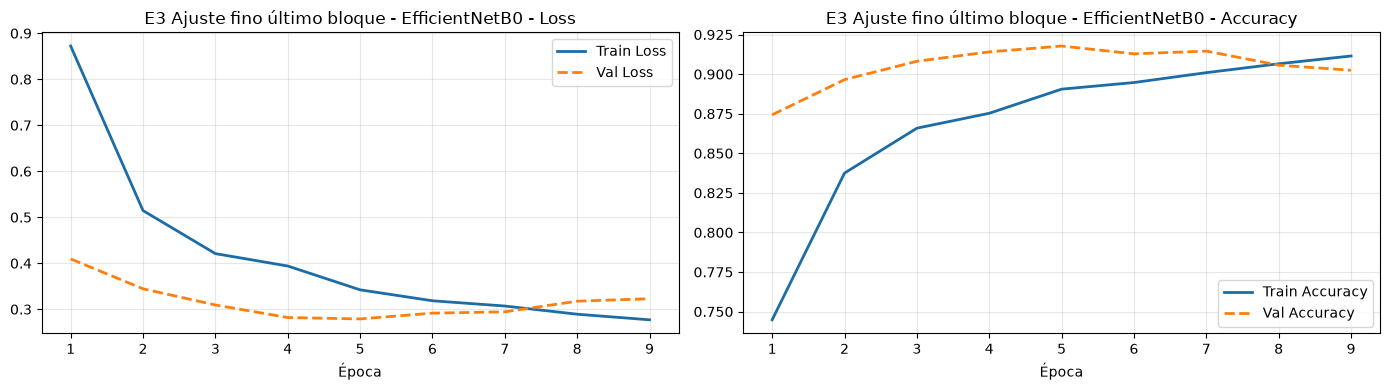

✓ [E3 Ajuste fino último bloque - EfficientNetB0] Train 92.81% | Val 91.78% | Test 92.32% | 3,486,246 parámetros entrenables | 702 s


In [9]:
for name in TOP_MODELS:
    reset_seed()
    model, base = build_end_to_end(name)
    model.set_weights(e2_weights[name])  # mismo modelo y mismos pesos que al final de la estrategia 2
    base.trainable = True
    for layer in base.layers:
        layer.trainable = LAST_BLOCK[name](layer.name)
    print(f"\n===== {name}: {count_trainable(model):,} parámetros entrenables de {model.count_params():,} =====")
    train_and_log(f"E3 Ajuste fino último bloque - {name}", "3. Ajuste fino parcial", name, model,
                  keras.optimizers.Adam(1e-5), epochs=15, patience=4)

### Comentarios de la Estrategia 3
* Descongelar el último bloque mejora algo la estrategia 2 en ResNet50 (93,60% en validación) y prácticamente nada en EfficientNetB0 (91,78%), pero **ninguna de las dos alcanza la estrategia 1**.
* El "último bloque" no es pequeño: son 15,5 M de parámetros en ResNet50 (`conv5`, el 64% de la red) y 3,5 M en EfficientNetB0 (`block6`-`block7`-`top`, el 80%). Las últimas etapas de una CNN concentran casi todos los parámetros porque tienen muchos canales.
* En ResNet50 la validación sube hasta el 93,6% en la época 3 y después vuelve a oscilar (89-92%), aunque la exactitud de entrenamiento sigue subiendo. Con una tasa de $10^{-5}$ constante y la cabeza heredada de la estrategia 2, el ajuste fino no termina de estabilizarse. EfficientNetB0 empieza con una caída (87,4% en la primera época) y no supera el 91,8%.

<a id="sec7"></a>
## 7. Estrategia 4: Ajuste Fino Completo

Igual que la estrategia 3, pero **descongelando toda la base**. Las imágenes de satélite se parecen poco a las fotos de ImageNet, así que también las capas intermedias podrían adaptarse con provecho. A cambio hay muchos más parámetros entrenables y más riesgo de sobreajuste, y cada época es más lenta. Adam $10^{-5}$ con `ReduceLROnPlateau` (divide la tasa entre 2 si `val_loss` no mejora en 2 épocas), hasta 15 épocas y Early Stopping con paciencia 4.


===== ResNet50: 24,061,706 parámetros entrenables de 24,114,826 =====


Época   1 | loss 0.5541 acc 0.8427 | val_loss 0.3157 val_acc 0.8998


Época   2 | loss 0.2565 acc 0.9198 | val_loss 0.2192 val_acc 0.9331


Época   3 | loss 0.2034 acc 0.9375 | val_loss 0.1970 val_acc 0.9410


Época   4 | loss 0.1703 acc 0.9478 | val_loss 0.1660 val_acc 0.9504


Época   5 | loss 0.1406 acc 0.9570 | val_loss 0.1838 val_acc 0.9469


... (6 outputs left out)

Época  12 | loss 0.0760 acc 0.9759 | val_loss 0.1117 val_acc 0.9672


Época  13 | loss 0.0754 acc 0.9764 | val_loss 0.1220 val_acc 0.9664


Época  14 | loss 0.0710 acc 0.9770 | val_loss 0.1229 val_acc 0.9649


Época  15 | loss 0.0659 acc 0.9793 | val_loss 0.1213 val_acc 0.9672


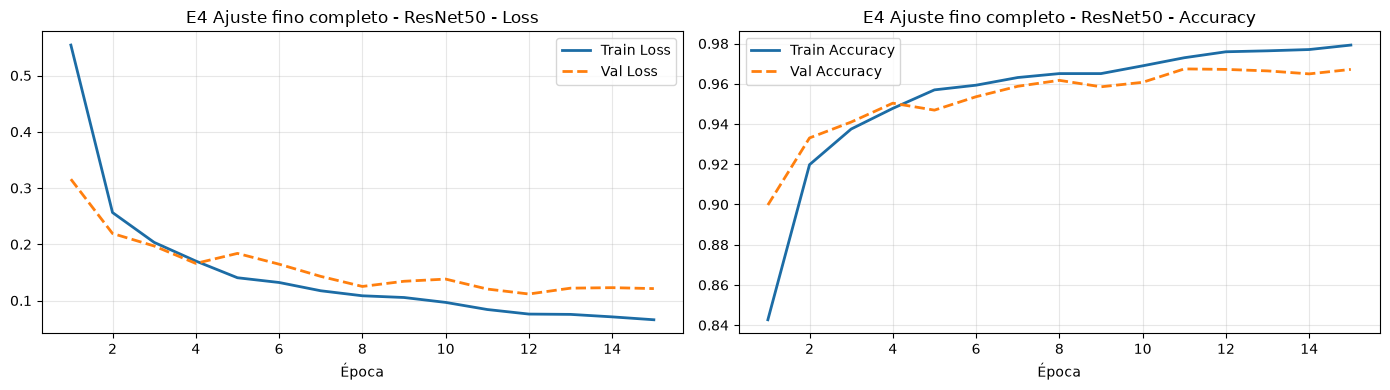

✓ [E4 Ajuste fino completo - ResNet50] Train 97.83% | Val 96.72% | Test 96.86% | 24,061,706 parámetros entrenables | 2874 s



===== EfficientNetB0: 4,338,054 parámetros entrenables de 4,380,077 =====


E0000 00:00:1794952247.427561     742 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_e2e_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


Época   1 | loss 1.3971 acc 0.6101 | val_loss 0.6522 val_acc 0.7864


Época   2 | loss 0.6048 acc 0.8035 | val_loss 0.4731 val_acc 0.8407


Época   3 | loss 0.4620 acc 0.8507 | val_loss 0.3852 val_acc 0.8760


... (8 outputs left out)

Época  12 | loss 0.1987 acc 0.9341 | val_loss 0.2526 val_acc 0.9202


Época  13 | loss 0.1828 acc 0.9423 | val_loss 0.2505 val_acc 0.9200


Época  14 | loss 0.1828 acc 0.9398 | val_loss 0.2351 val_acc 0.9247


Época  15 | loss 0.1686 acc 0.9442 | val_loss 0.2273 val_acc 0.9257


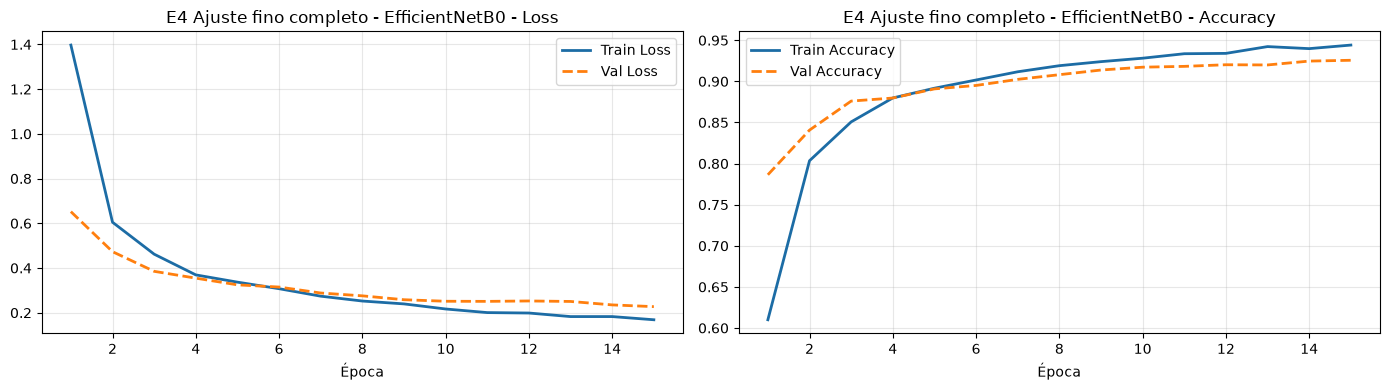

✓ [E4 Ajuste fino completo - EfficientNetB0] Train 94.08% | Val 92.57% | Test 93.51% | 4,338,054 parámetros entrenables | 2328 s


In [10]:
for name in TOP_MODELS:
    reset_seed()
    model, base = build_end_to_end(name)
    model.set_weights(e2_weights[name])
    base.trainable = True  # toda la base entrenable
    print(f"\n===== {name}: {count_trainable(model):,} parámetros entrenables de {model.count_params():,} =====")
    train_and_log(f"E4 Ajuste fino completo - {name}", "4. Ajuste fino completo", name, model,
                  keras.optimizers.Adam(1e-5), epochs=15, patience=4,
                  extra_callbacks=[callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)])

### Comentarios de la Estrategia 4
* **ResNet50 da el mejor resultado de las estrategias 1-4: 96,72% en validación y 96,86% en test**, con la pérdida de test más baja hasta aquí (0,087). Cuando toda la red se adapta, también las capas intermedias aprenden texturas propias de las imágenes de satélite. La curva sube de forma continua durante las 15 épocas, así que con más épocas habría seguido mejorando.
* **Pero el coste es muy alto:** 2.874 s (48 minutos) para ResNet50, 40 veces más que la estrategia 1, para ganar 0,5 puntos de validación.
* **EfficientNetB0 sale mal parada:** su validación **cae del 91,33% (final de la estrategia 2) al 78,64% en la primera época** y en 15 épocas solo se recupera hasta el 92,57%, por debajo de su estrategia 1. Descongelar la red entera ha estropeado al principio parte de lo aprendido. La causa se analiza en la sección siguiente.

---
### 7.1. Diagnóstico y Estrategia 5: Ajuste Fino Completo Corregido

Las estrategias 2 y 3 quedan **por debajo de la estrategia 1**, la más sencilla, y la 4 solo la supera en ResNet50 y a un coste 40 veces mayor. Los resultados anteriores muestran tres causas:

1. **Aumento de datos con la base congelada (estrategia 2).** Si la base no se entrena, no puede aprender a dar el mismo vector para una imagen y para su versión girada, desplazada o ampliada: esa invariancia tiene que aprenderla la cabeza sola, a partir de unas características fijas. El resultado es **infrajuste**: entrenamiento ~92,6% frente al ~99% de la estrategia 1. Además, la validación oscila y `EarlyStopping` (paciencia 4) corta el entrenamiento en la época 7-8. En la estrategia 1 la brecha era de solo ~3 puntos, así que no hacía falta tanta regularización.
2. **Las estrategias 3 y 4 heredan esa cabeza peor:** empiezan desde ~91-92% de validación en lugar del ~96% de la estrategia 1, y parte de las épocas de ajuste fino se dedican solo a recuperar ese terreno.
3. **Batch Normalization descongelada.** Al descongelar la base también se volvieron entrenables los parámetros $\gamma$ (escala) y $\beta$ (desplazamiento) de sus capas BN. En EfficientNetB0 la exactitud de validación **cayó del 91,33% al 78,64% en la primera época de la estrategia 4**. Adam mueve cada peso aproximadamente la misma cantidad (del orden de $\eta$) sea cual sea el tamaño de su gradiente, así que también cambia la escala de las activaciones normalizadas, que la red preentrenada necesita mantener. EfficientNetB0 tiene una capa BN tras casi cada convolución y es la más afectada. La guía de *transfer learning* de Keras recomienda **mantener congeladas las capas BN** al hacer ajuste fino.

Además, los registros muestran que **el aumento de datos completo (giros, desplazamientos y zoom) triplicaba el tiempo de cada época**: ~190 s por época en la estrategia 4 con ResNet50, frente a los ~63 s de la estrategia 5, que solo aplica volteos.

**Corrección (Estrategia 5):**
* **Partimos de la cabeza de la estrategia 1** (la mejor), copiando sus pesos en el modelo completo: el ajuste fino empieza desde ~96%.
* **Toda la base entrenable menos las capas de Batch Normalization**, que quedan congeladas.
* **Solo volteos horizontales y verticales** como aumento de datos. Son simetrías exactas de una imagen tomada desde arriba: no interpolan píxeles ni crean bordes artificiales por reflexión.
* **Programa fijo de tasa de aprendizaje** (la lección del cuaderno 1): 1 época de calentamiento hasta $2 \cdot 10^{-5}$ y decaimiento coseno hasta 0 en 10 épocas, sin `EarlyStopping`.


===== ResNet50: 24,008,586 parámetros entrenables de 24,114,826 | exactitud de validación al empezar: 96.22% =====


Época   1 | loss 0.1159 acc 0.9604 | val_loss 0.1455 val_acc 0.9516


Época   2 | loss 0.1078 acc 0.9643 | val_loss 0.0975 val_acc 0.9699


Época   3 | loss 0.0731 acc 0.9761 | val_loss 0.1243 val_acc 0.9607


Época   4 | loss 0.0562 acc 0.9814 | val_loss 0.0787 val_acc 0.9726


Época   5 | loss 0.0382 acc 0.9870 | val_loss 0.0592 val_acc 0.9832


Época   6 | loss 0.0271 acc 0.9917 | val_loss 0.0639 val_acc 0.9827


Época   7 | loss 0.0191 acc 0.9941 | val_loss 0.0597 val_acc 0.9822


Época   8 | loss 0.0109 acc 0.9962 | val_loss 0.0675 val_acc 0.9820


Época   9 | loss 0.0072 acc 0.9980 | val_loss 0.0611 val_acc 0.9837


Época  10 | loss 0.0066 acc 0.9978 | val_loss 0.0617 val_acc 0.9830


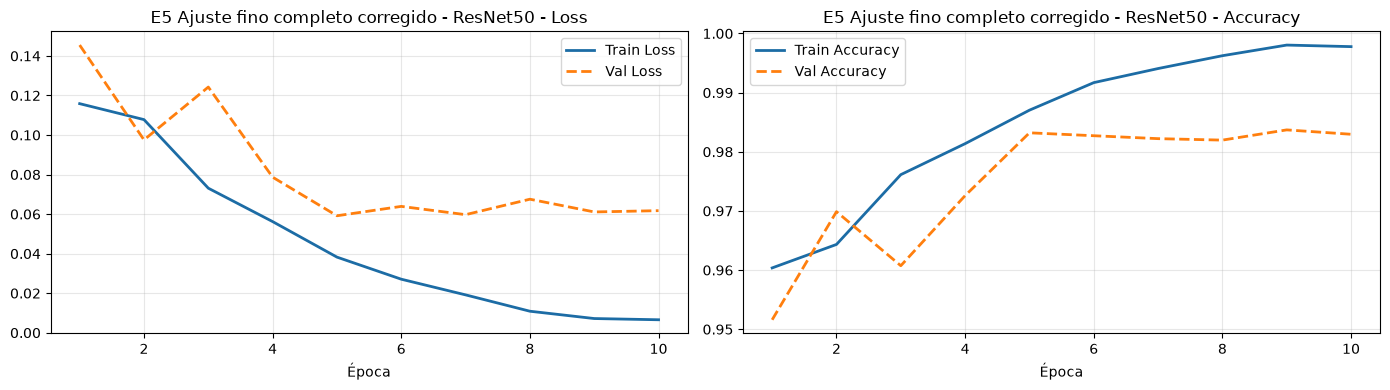

✓ [E5 Ajuste fino completo corregido - ResNet50] Train 99.94% | Val 98.30% | Test 98.57% | 24,008,586 parámetros entrenables | 634 s



===== EfficientNetB0: 4,296,038 parámetros entrenables de 4,380,077 | exactitud de validación al empezar: 96.15% =====


E0000 00:00:1794955318.607119     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794955319.382089     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794955321.615988     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794955377.221188     802 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (8 outputs left out)

Época   7 | loss 0.0399 acc 0.9861 | val_loss 0.0735 val_acc 0.9763


Época   8 | loss 0.0367 acc 0.9877 | val_loss 0.0715 val_acc 0.9760


Época   9 | loss 0.0321 acc 0.9897 | val_loss 0.0721 val_acc 0.9773


Época  10 | loss 0.0331 acc 0.9884 | val_loss 0.0716 val_acc 0.9765


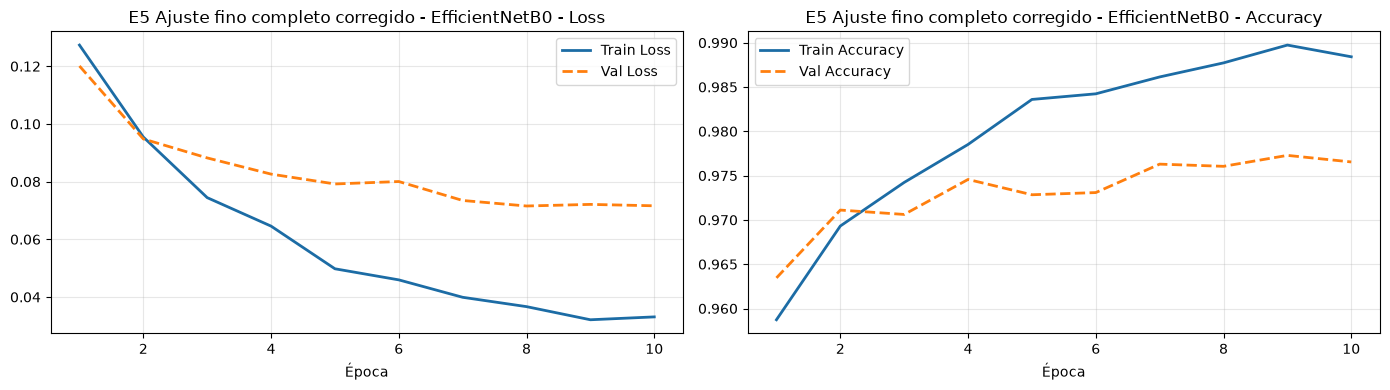

✓ [E5 Ajuste fino completo corregido - EfficientNetB0] Train 99.62% | Val 97.65% | Test 97.98% | 4,296,038 parámetros entrenables | 394 s


In [11]:
EPOCHS_FT = 10
steps_per_epoch = int(train_ds.cardinality())

def ft_schedule(peak=2e-5):
    return keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=0.0, warmup_target=peak, warmup_steps=steps_per_epoch,
        decay_steps=(EPOCHS_FT - 1) * steps_per_epoch)

for name in TOP_MODELS:
    reset_seed()
    model, base = build_end_to_end(name, aug="flips")
    # 1) copiamos la cabeza entrenada en la estrategia 1 (mismas capas: Dense(256) y Dense(10))
    head_e1 = models_registry[f"E1 Extracción rápida - {name} ({IMG_SIZE}px)"]
    dense_e2e = [l for l in model.layers if isinstance(l, layers.Dense)]
    dense_e1 = [l for l in head_e1.layers if isinstance(l, layers.Dense)]
    for dst, src in zip(dense_e2e, dense_e1):
        dst.set_weights(src.get_weights())
    # 2) toda la base entrenable salvo Batch Normalization
    base.trainable = True
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
    _, start_acc = model.evaluate(val_ds, verbose=0)
    print(f"\n===== {name}: {count_trainable(model):,} parámetros entrenables de {model.count_params():,} | "
          f"exactitud de validación al empezar: {start_acc*100:.2f}% =====")
    # 3) programa fijo de calentamiento + coseno, sin Early Stopping
    train_and_log(f"E5 Ajuste fino completo corregido - {name}", "5. Ajuste fino corregido", name, model,
                  keras.optimizers.Adam(learning_rate=ft_schedule()), epochs=EPOCHS_FT, patience=None)

### Comentarios de la Estrategia 5
* **Es la mejor estrategia con diferencia: ResNet50 alcanza un 98,30% en validación y un 98,57% en test**, y EfficientNetB0 un 97,65% y un 97,98%. Son las pérdidas de test más bajas de todo el trabajo (0,056 y 0,061).
* **La copia de la cabeza funciona:** antes de entrenar, el modelo completo ya da el 96,22% (ResNet50) y el 96,15% (EfficientNetB0) en validación, exactamente los valores de la estrategia 1. Durante la época de calentamiento hay un pequeño descenso (95,2% en ResNet50) y después la validación sube hasta el 98,3% en la época 5 y se mantiene estable (98,2-98,4%) mientras la tasa decae.
* **Sin caídas al descongelar:** con BN congelada, EfficientNetB0 no se desploma como en la estrategia 4 (de 96,15% pasa a 96,35% en la primera época) y mejora **4,5 puntos en test** respecto a su estrategia 4.
* **Y es mucho más barata:** 634 s (ResNet50) y 394 s (EfficientNetB0), entre 4,5 y 6 veces menos que la estrategia 4. Hacen falta 10 épocas en lugar de 15, cada época es 3 veces más rápida (solo volteos) y se parte de una cabeza ya buena. Contando también la estrategia 1 previa (~1 minuto), el total sigue siendo muy inferior.
* La brecha de entrenamiento es de 1,6-2,0 puntos (ResNet50 llega al 99,94% en entrenamiento): hay algo de sobreajuste, pero muy controlado.
* **ResNet50 frente a EfficientNetB0:** ResNet50 gana por 0,6 puntos en test, pero tiene 5,5 veces más parámetros (24,1 M frente a 4,4 M) y tarda un 60% más. Si importara el coste de inferencia, EfficientNetB0 sería la elección razonable.

<a id="sec8"></a>
## 8. Comparación Global

### 8.1. Todas las redes preentrenadas y estrategias

TABLA RESUMEN - CNN PREENTRENADAS EN EUROSAT (224 px)


,Estrategia,Red base,Parámetros entrenables,Épocas,Train Acc (%),Val Acc (%),Test Acc (%),Brecha Train-Val (pp),Test Loss,Tiempo (s)
E1 Extracción rápida - VGG16 (224px),1. Extracción rápida,VGG16,133898,34,98.81,95.11,95.33,3.7,0.1424,140.6
E1 Extracción rápida - ResNet50 (224px),1. Extracción rápida,ResNet50,527114,20,99.29,96.22,96.44,3.07,0.1078,70.2
E1 Extracción rápida - DenseNet121 (224px),1. Extracción rápida,DenseNet121,264970,28,98.42,95.93,95.56,2.5,0.1203,96.9
E1 Extracción rápida - MobileNetV2 (224px),1. Extracción rápida,MobileNetV2,330506,31,98.74,94.44,94.32,4.29,0.178,114.0
E1 Extracción rápida - EfficientNetB0 (224px),1. Extracción rápida,EfficientNetB0,330506,18,98.64,96.15,96.27,2.49,0.1072,58.0
E1 Extracción rápida - ConvNeXtTiny (224px),1. Extracción rápida,ConvNeXtTiny,199434,26,99.37,95.14,95.33,4.23,0.1409,98.4
E2 Extracción + aumento - ResNet50,2. Extracción + aumento,ResNet50,527114,7,92.56,91.73,92.44,0.83,0.238,355.5
E2 Extracción + aumento - EfficientNetB0,2. Extracción + aumento,EfficientNetB0,330506,8,92.6,91.33,93.11,1.26,0.22,312.6
E3 Ajuste fino último bloque - ResNet50,3. Ajuste fino parcial,ResNet50,15503114,7,94.72,93.6,94.05,1.12,0.1843,502.0
E3 Ajuste fino último bloque - EfficientNetB0,3. Ajuste fino parcial,EfficientNetB0,3486246,9,92.81,91.78,92.32,1.03,0.263,702.3


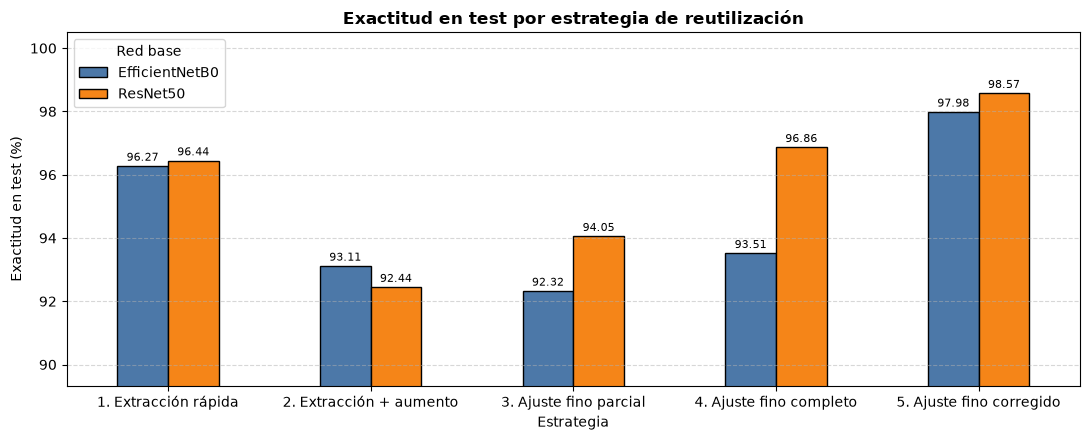

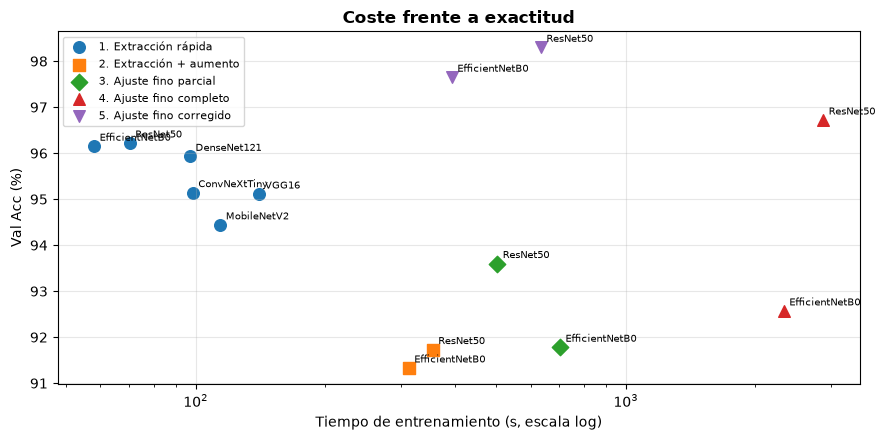

In [12]:
df_pre = pd.DataFrame(results_registry).T
df_pre_224 = df_pre[df_pre["Resolución"] == IMG_SIZE]
cols = ["Estrategia", "Red base", "Parámetros entrenables", "Épocas", "Train Acc (%)", "Val Acc (%)",
        "Test Acc (%)", "Brecha Train-Val (pp)", "Test Loss", "Tiempo (s)"]
print("=" * 100)
print("TABLA RESUMEN - CNN PREENTRENADAS EN EUROSAT (224 px)")
print("=" * 100)
display(df_pre_224[cols])

# Gráfico: exactitud en test por estrategia para las 2 redes que pasaron a las estrategias 2-4
pivot = df_pre_224[df_pre_224["Red base"].isin(TOP_MODELS)].pivot(index="Estrategia", columns="Red base",
                                                                    values="Test Acc (%)").astype(float)
ax = pivot.plot(kind="bar", figsize=(11, 4.5), edgecolor="black", color=["#4c78a8", "#f58518"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(pivot.min().min() - 3, 100.5); ax.set_ylabel("Exactitud en test (%)")
ax.set_title("Exactitud en test por estrategia de reutilización", fontweight="bold")
plt.xticks(rotation=0); ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Coste frente a resultado
fig, ax = plt.subplots(figsize=(9, 4.5))
for strat, marker in zip(sorted(df_pre_224["Estrategia"].unique()), "osD^v"):
    sub = df_pre_224[df_pre_224["Estrategia"] == strat]
    ax.scatter(sub["Tiempo (s)"].astype(float), sub["Val Acc (%)"].astype(float), s=70, marker=marker, label=strat)
    for _, r in sub.iterrows():
        ax.annotate(r["Red base"], (float(r["Tiempo (s)"]), float(r["Val Acc (%)"])), fontsize=7,
                    textcoords="offset points", xytext=(4, 4))
ax.set_xscale("log"); ax.set_xlabel("Tiempo de entrenamiento (s, escala log)"); ax.set_ylabel("Val Acc (%)")
ax.set_title("Coste frente a exactitud", fontweight="bold"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8.2. P1 frente a P2: red densa, CNN personalizada y CNN preentrenada
Los resultados de la CNN personalizada se leen del fichero que guarda el cuaderno 1. Los de la P1 están copiados de la tabla final de su cuaderno. Las tres prácticas usan **el mismo conjunto de test**.

Mejor modelo preentrenado (por validación): E5 Ajuste fino completo corregido - ResNet50


,Test Acc (%),Val Acc (%),Parámetros
P1: MLP con Early Stopping,65.09,NaN,6457482.0
"P2 CNN personalizada: Modelo 9 (Aug+BN+Dropout 0.3, coseno 100 ép.)",96.15,95.7,306154.0
P2 preentrenada: E5 Ajuste fino completo corregido - ResNet50,98.57,98.3,24114826.0


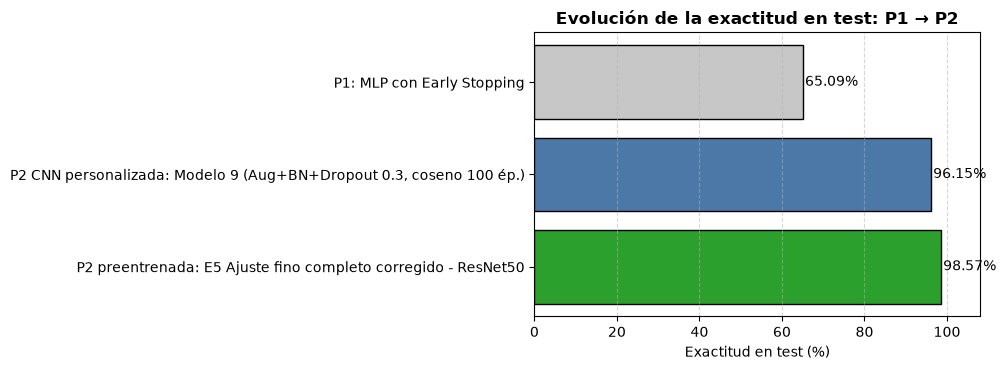

In [13]:
P1_BEST = ("P1: MLP con Early Stopping", 65.09)
P1_F1 = {"AnnualCrop": 0.58, "Forest": 0.85, "HerbaceousVegetation": 0.58, "Highway": 0.30, "Industrial": 0.82,
         "Pasture": 0.71, "PermanentCrop": 0.52, "Residential": 0.63, "River": 0.58, "SeaLake": 0.82}

with open(os.path.join(RESULTS_DIR, "p2_1_cnn_personalizada.json"), encoding="utf-8") as f:
    cnn = json.load(f)
cnn_rows = {r["Modelo"]: r for r in cnn["results"]}
cnn_best = cnn_rows[cnn["best_model"]]

best_pre_key = df_pre["Val Acc (%)"].astype(float).idxmax()  # el mejor se elige por VALIDACIÓN
best_pre = df_pre.loc[best_pre_key]
print("Mejor modelo preentrenado (por validación):", best_pre_key)

final = pd.DataFrame({
    "Test Acc (%)": [P1_BEST[1], cnn_best["Test Acc (%)"], best_pre["Test Acc (%)"]],
    "Val Acc (%)": [np.nan, cnn_best["Val Acc (%)"], best_pre["Val Acc (%)"]],
    "Parámetros": [6_457_482, cnn_best["Parámetros"], best_pre["Parámetros totales"]],
}, index=[P1_BEST[0], f"P2 CNN personalizada: {cnn['best_model']}", f"P2 preentrenada: {best_pre_key}"])
display(final)

fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(final.index, final["Test Acc (%)"].astype(float), color=["#c7c7c7", "#4c78a8", "#2ca02c"], edgecolor="black")
for bar in bars:
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.2f}%", va="center")
ax.set_xlim(0, 108); ax.set_xlabel("Exactitud en test (%)"); ax.invert_yaxis()
ax.set_title("Evolución de la exactitud en test: P1 → P2", fontweight="bold"); ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 8.3. Matriz de confusión y F1 por clase del mejor modelo preentrenado

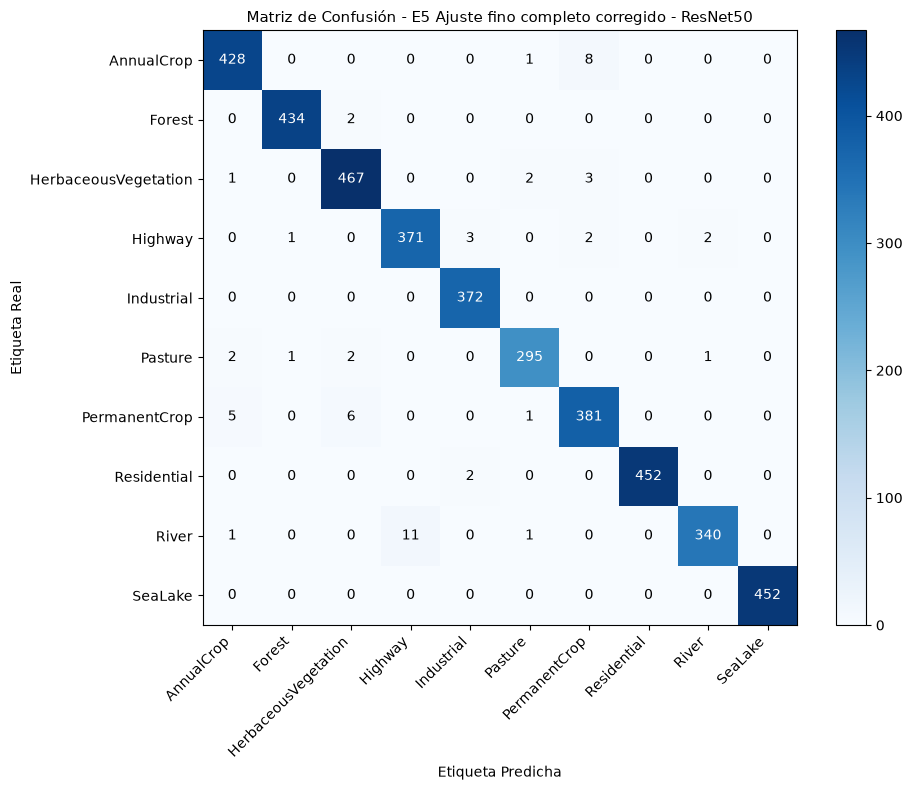

                      precision    recall  f1-score   support

          AnnualCrop      0.979     0.979     0.979       437
              Forest      0.995     0.995     0.995       436
HerbaceousVegetation      0.979     0.987     0.983       473
             Highway      0.971     0.979     0.975       379
          Industrial      0.987     1.000     0.993       372
             Pasture      0.983     0.980     0.982       301
       PermanentCrop      0.967     0.969     0.968       393
         Residential      1.000     0.996     0.998       454
               River      0.991     0.963     0.977       353
             SeaLake      1.000     1.000     1.000       452

            accuracy                          0.986      4050
           macro avg      0.985     0.985     0.985      4050
        weighted avg      0.986     0.986     0.986      4050



,P1 (MLP),P2 CNN personalizada,P2 preentrenada
AnnualCrop,0.58,0.947,0.979
Forest,0.85,0.964,0.995
HerbaceousVegetation,0.58,0.959,0.983
Highway,0.30,0.968,0.975
Industrial,0.82,0.977,0.993
Pasture,0.71,0.959,0.982
PermanentCrop,0.52,0.936,0.968
Residential,0.63,0.973,0.998
River,0.58,0.959,0.977
SeaLake,0.82,0.970,1.000


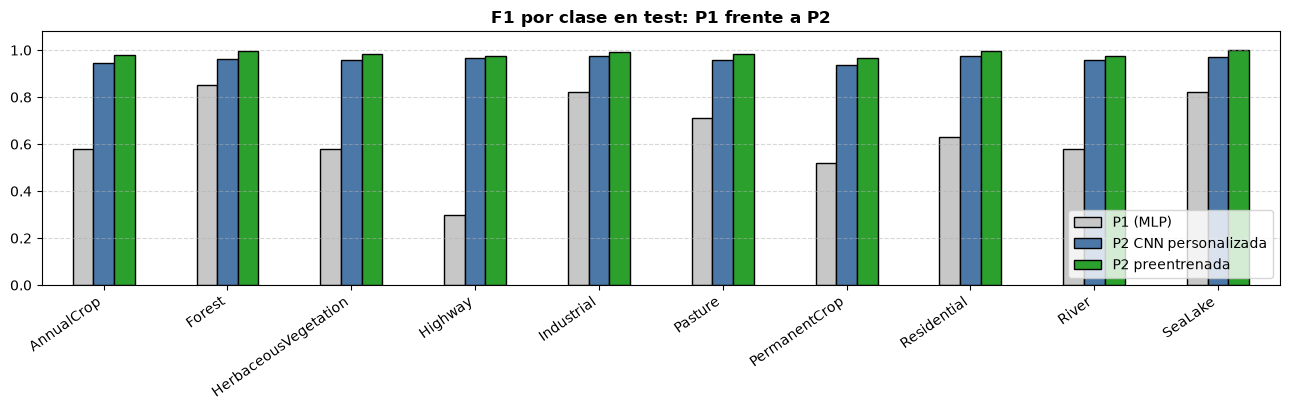

In [14]:
best_model = models_registry[best_pre_key]
probs = best_model.predict(test_ds, verbose=0)
y_true_all, y_pred_all = y_test.argmax(1), probs.argmax(1)

cm = confusion_matrix(y_true_all, y_pred_all)
plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title(f"Matriz de Confusión - {best_pre_key}", fontsize=11)
plt.colorbar()
ticks = np.arange(num_classes)
plt.xticks(ticks, class_names, rotation=45, ha="right"); plt.yticks(ticks, class_names)
thresh = cm.max() / 2.
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, format(cm[i, j], "d"), ha="center", va="center", color="white" if cm[i, j] > thresh else "black")
plt.ylabel("Etiqueta Real"); plt.xlabel("Etiqueta Predicha")
plt.tight_layout()
plt.show()

report = classification_report(y_true_all, y_pred_all, target_names=class_names, output_dict=True)
print(classification_report(y_true_all, y_pred_all, target_names=class_names, digits=3))

f1 = pd.DataFrame({"P1 (MLP)": P1_F1,
                   "P2 CNN personalizada": {c: round(cnn["per_class_f1"][c], 3) for c in class_names},
                   "P2 preentrenada": {c: round(report[c]["f1-score"], 3) for c in class_names}})
display(f1)
f1.plot(kind="bar", figsize=(13, 4.2), color=["#c7c7c7", "#4c78a8", "#2ca02c"], edgecolor="black")
plt.title("F1 por clase en test: P1 frente a P2", fontweight="bold")
plt.ylim(0, 1.08); plt.xticks(rotation=35, ha="right"); plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [15]:
summary = {
    "results": df_pre.reset_index(names="Experimento").to_dict(orient="records"),
    "best_model": best_pre_key,
    "top_models": TOP_MODELS,
    "per_class_f1": {c: report[c]["f1-score"] for c in class_names},
}
with open(os.path.join(RESULTS_DIR, "p2_2_cnn_preentrenadas.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", os.path.join(RESULTS_DIR, "p2_2_cnn_preentrenadas.json"))

Resultados guardados en resultados/p2_2_cnn_preentrenadas.json


<a id="sec9"></a>
## 9. Conclusiones
### 1. Resultado final y comparación P1 → P2
| Modelo | Test Acc | Parámetros | Errores en test (de 4.050) |
|---|---|---|---|
| P1: MLP (mejor modelo) | 65,09% | 6,46 M | ~1.414 |
| P2: CNN personalizada (Modelo 9) | 96,15% | 0,31 M | 156 |
| P2: ResNet50, extracción rápida (estrategia 1) | 96,44% | 24,1 M (0,53 M entrenables) | ~144 |
| **P2: ResNet50, ajuste fino corregido (estrategia 5)** | **98,57%** | 24,1 M | **58** |

* Se cumple lo que anticipa el enunciado: **CNN personalizada > red densa** (+31 puntos) y **CNN preentrenada > CNN personalizada** (+2,4 puntos, con un **63% menos de errores**: de 156 a 58).
* En F1 por clase, el modelo preentrenado es el mejor en **las 10 clases**, todas por encima de 0,96. La diferencia más pequeña con la CNN personalizada está en Highway (0,975 frente a 0,968). **SeaLake es perfecta (452/452)**: desaparecen los errores de mar oscuro → bosque que tenía la CNN propia (14). Las confusiones que quedan son River → Highway (11), por la forma alargada que comparten, y entre clases agrícolas: AnnualCrop → PermanentCrop (8), PermanentCrop → HerbaceousVegetation (6).

### 2. ¿Qué estrategia de reutilización es mejor?
* **Extracción rápida de características (E1):** la mejor relación calidad/coste. Con ~1 minuto y sin entrenar la base ya iguala o supera a la CNN diseñada a mano. Es la primera estrategia que conviene probar.
* **Extracción con aumento de datos (E2):** peor que E1 en este problema. Con la base congelada, el aumento de datos complica la tarea de la cabeza sin aportar nada, porque E1 apenas sobreajustaba. Además, es 5 veces más cara.
* **Ajuste fino parcial y completo (E3, E4):** solo el completo de ResNet50 supera a E1, y a un coste 40 veces mayor. Dependen mucho de **cómo** se haga el ajuste fino.
* **Ajuste fino completo corregido (E5): la mejor.** Lo decisivo fue: (1) partir de una cabeza ya bien entrenada (la de E1), (2) mantener congeladas las capas de Batch Normalization, (3) usar solo aumentos de datos que son simetrías exactas y (4) usar un programa fijo de calentamiento y decaimiento coseno en lugar de reaccionar a una validación ruidosa.

### 3. Comparación entre redes
* Con las características fijas, ResNet50, EfficientNetB0 y DenseNet121 son las mejores (≥95,9% en validación). Ni la red más moderna (ConvNeXtTiny) ni la del Laboratorio 7 (VGG16) son las mejores, y la más ligera (MobileNetV2) es la peor.
* EfficientNetB0 ofrece casi el mismo resultado que ResNet50 (97,98% frente a 98,57% en E5) con 5,5 veces menos parámetros.
* **Ampliar las imágenes de 64 a 224 px** es imprescindible para aprovechar las redes preentrenadas: +3,8 puntos en la extracción rápida de ResNet50.

### 4. Ventajas e inconvenientes: preentrenada frente a personalizada
* **Preentrenada:** más exacta (+2,4 puntos) y, en su versión más sencilla, más rápida de obtener (1 minuto). Pero los modelos son 14 (EfficientNetB0) o 79 (ResNet50) veces más grandes que la CNN propia, y cada imagen se procesa a 224x224 en lugar de 64x64, así que cada predicción es mucho más cara.
* **Personalizada:** 0,31 M de parámetros, procesa la imagen a su tamaño original y se puede entender capa a capa. A cambio, exige un diseño y un ajuste de hiperparámetros largos (cuaderno 1) y llega 2,4 puntos por debajo.

### 5. Lección metodológica común a los dos cuadernos
En ambos cuadernos, la primera combinación "lógica" de técnicas (Modelos 7 y 8 en el cuaderno 1, estrategias 2-4 aquí) dio peores resultados que opciones más simples. Las curvas de entrenamiento permitieron diagnosticar las causas (validación inestable por BN, infrajuste por exceso de regularización, punto de partida malo del ajuste fino), y la misma receta lo corrigió en los dos casos: **menos regularización redundante y un programa fijo de tasa de aprendizaje con calentamiento y decaimiento coseno**. Todas las decisiones se tomaron con el conjunto de validación, y el test solo se ha usado para informar de los resultados.